# Notebook A: dữ liệu, làm sạch, SQL và hình RQ1

**Đề tài:** Mô hình thay thế cho trang trại điện sóng cần bao nhiêu bố trí mô phỏng và có chuyển được sang vùng biển và quy mô khác hay không

**Sinh viên A** chạy lần lượt từ trên xuống. Mỗi ô code có một ô hướng dẫn ngay phía trên gồm ba ý: làm gì, vì sao, kiểm tra gì. Sản phẩm bàn giao cho Notebook B là file parquet trong `data/processed/`, file `sql/queries.sql` và `data/processed/manifest.json`.

## Bước 0. Môi trường

- **Làm gì:** cài thư viện (một lần), tạo thư mục, nạp ba hàm tiện ích.
- **Vì sao:** hai notebook của nhóm dùng chung cấu trúc thư mục để bàn giao file cho nhau.
- **Kiểm tra:** ô chạy xong không báo lỗi.

In [2]:
# run once per machine, then comment out
%pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

## Bước 1a. Tải dữ liệu

- **Làm gì:** tải file gốc về `data/raw/` và giải nén. Ô này bỏ qua nếu dữ liệu đã có.
- **Vì sao:** người khác chạy lại notebook phải nhận đúng cùng một bộ dữ liệu.
- **Kiểm tra:** ô in đường dẫn của từng file cần có. Nếu tải tự động lỗi hoặc thiếu file, tải tay tại `archive.ics.uci.edu/dataset/882`, chép vào `data/raw/` rồi chạy lại ô này.

In [4]:
FILES = [('https://archive.ics.uci.edu/static/public/882/large-scale+wave+energy+farm.zip', 'wavefarm.zip')]
NEED = ['WEC_*49*.csv', 'WEC_*100*.csv']
have = lambda: [glob.glob('data/raw/**/' + n, recursive=True) for n in NEED]
if not all(have()):
    for url, name in FILES:
        try: fetch(url, name)
        except Exception as e: print('download failed:', name, e)
    unzip_all()
for n, hit in zip(NEED, have()):
    assert hit, 'missing ' + n + ': download by hand from archive.ics.uci.edu/dataset/882 into data/raw and run this cell again'
    print(n, '->', hit[0], os.path.getsize(hit[0]) // 1024, 'kB')

downloading https://archive.ics.uci.edu/static/public/882/large-scale+wave+energy+farm.zip
WEC_*49*.csv -> data/raw\WEC_Perth_49.csv 32871 kB
WEC_*100*.csv -> data/raw\WEC\WEC_Perth_100.csv 15406 kB


## Bước 1b. Nạp dữ liệu

- **Làm gì:** đọc file gốc, tạo bảng làm việc.
- **Vì sao:** mọi bước sau dùng bảng này, nên số dòng và số cột in ra ở đây là con số ghi vào mục Data của bài.
- **Kiểm tra:** so số dòng, số cột với mô tả của bộ dữ liệu trong đề cương; nếu khác thì ghi lại con số thật.

In [5]:
# Step 1b: Large-scale Wave Energy Farm (Neshat et al.; UCI 2023): 63,600 simulated layouts of 49 or 100 wave energy converters at Perth and Sydney
# download (one zip, 17 MB, no account): https://archive.ics.uci.edu/static/public/882/large-scale+wave+energy+farm.zip
import pandas as pd, numpy as np, glob, re, os
def geometry(P):                                         # P: layouts x converters x 2 coordinates -> features that do not depend on the farm size
    out = []
    for i in range(0, len(P), 2000):
        Q = P[i:i + 2000]; D = np.sqrt(((Q[:, :, None, :] - Q[:, None, :, :]) ** 2).sum(-1)); n = Q.shape[1]
        D[:, np.arange(n), np.arange(n)] = np.inf; nn = D.min(2); D[:, np.arange(n), np.arange(n)] = np.nan
        out.append(np.c_[nn.mean(1), nn.min(1), nn.std(1), np.nanmean(D, (1, 2)), (nn < 100).mean(1), Q[:, :, 0].std(1), Q[:, :, 1].std(1),
                         np.ptp(Q[:, :, 0], 1), np.ptp(Q[:, :, 1], 1), np.nanmean(D < 200, (1, 2)), np.nanmean(D < 400, (1, 2))])
    return pd.DataFrame(np.vstack(out), columns=GEO)
GEO = ['nn_mean', 'nn_min', 'nn_std', 'pair_mean', 'share_closer_100m', 'x_std', 'y_std', 'x_range', 'y_range', 'pairs_within_200m', 'pairs_within_400m']
parts, raw49 = [], []
_files = {}                                              # the UCI zip also unpacks nested copies, so load each file name once
for _f in sorted(glob.glob('data/raw/**/WEC_*.csv', recursive=True)): _files.setdefault(os.path.basename(_f), _f)
assert len(_files) == 4, ('expected 4 distinct WEC files', sorted(_files))
for f in _files.values():
    site, n = re.findall(r'WEC_([A-Za-z]+)_(\d+)', os.path.basename(f))[0]; n = int(n); d = pd.read_csv(f); n_raw = len(d); d = d.drop_duplicates().reset_index(drop=True)   # identical simulated rows are one layout
    print(site, n, 'rows', n_raw, '-> distinct layouts', len(d))
    xs = sorted([c for c in d.columns if re.fullmatch(r'X\d+', c)], key=lambda c: int(c[1:])); ys = sorted([c for c in d.columns if re.fullmatch(r'Y\d+', c)], key=lambda c: int(c[1:]))
    assert len(xs) == n == len(ys), (f, len(xs)); g = geometry(np.stack([d[xs].to_numpy(float), d[ys].to_numpy(float)], axis=-1))
    g['site'] = site; g['n_wec'] = n; g['qW'] = d['qW'].to_numpy(); g['total_power'] = d['Total_Power'].to_numpy(); parts.append(g)
    if n == 49: raw49.append(pd.concat([d[xs + ys].reset_index(drop=True), g[['site', 'qW']]], axis=1))
df = pd.concat(parts, ignore_index=True); raw49 = pd.concat(raw49, ignore_index=True)
print(df.shape); print(df.groupby(['site', 'n_wec']).agg(layouts=('qW', 'size'), qW=('qW', 'mean'), power_MW=('total_power', lambda s: s.mean() / 1e6)))

Perth 100 rows 7277 -> distinct layouts 2737
Perth 49 rows 36043 -> distinct layouts 10936
Sydney 100 rows 2318 -> distinct layouts 1234
Sydney 49 rows 17964 -> distinct layouts 4816
(19723, 15)
              layouts        qW  power_MW
site   n_wec                             
Perth  49       10936  0.824585  3.893899
       100       2737  0.721995  6.959157
Sydney 49        4816  0.768916  3.985542
       100       1234  0.673744  7.127258


## Bước 2. Làm sạch có nhật ký

- **Làm gì:** kiểm tra miền giá trị, loại dòng lỗi, lưu parquet và nhật ký làm sạch.
- **Vì sao:** phản biện sẽ hỏi vì sao số dòng khác tài liệu gốc; nhật ký là câu trả lời.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`, mỗi dòng bị bỏ phải có lý do.

In [6]:
# Step 2: valid ranges, repeated layouts, cleaning log
log = [['layouts', len(df)], ['missing cells', int(df.isna().sum().sum())]]
ok = (df.qW > 0) & (df.total_power > 0) & np.isfinite(df[GEO]).all(axis=1); df = df[ok].reset_index(drop=True); raw49 = raw49[raw49.qW > 0]
log.append(['positive power and finite geometry', len(df)])
dup = df.duplicated(GEO + ['site', 'n_wec']); log.append(['layouts with identical geometry features (kept, flagged)', int(dup.sum())]); df['repeated'] = dup.astype(int)
df['power_per_wec_kW'] = df.total_power / df.n_wec / 1000; df['file'] = df.site + '_' + df.n_wec.astype(str); df['row_id'] = np.arange(len(df))
pd.DataFrame(log, columns=['step', 'value']).to_csv('report/table_cleaning_log.csv', index=False); print(log)
df.to_parquet('data/processed/wave.parquet', index=False); raw49.to_parquet('data/processed/wave_raw49.parquet', index=False); print(df.shape, raw49.shape)

[['layouts', 19723], ['missing cells', 0], ['positive power and finite geometry', 19723], ['layouts with identical geometry features (kept, flagged)', 718]]
(19723, 19) (15752, 100)


## Bước 2b. Hiểu dữ liệu trước khi đặt câu hỏi

Mười ô dưới đây đọc lại bảng đã làm sạch và trả lời lần lượt: bảng có những cột gì, phân phối ra sao, thiếu ở đâu, có giá trị lạ không, cột nào liên quan tới mục tiêu và mục tiêu khác nhau thế nào giữa các nhóm. **Quy tắc:** sau mỗi ô, nhóm viết một câu nhận xét có số vào dòng Nhận xét. Hình và mô hình chỉ tốt khi nhóm hiểu dữ liệu ở bước này.

### 2b.1 Nạp bảng sạch và xem năm dòng đầu

- **Làm gì:** đọc file parquet, chọn cột mục tiêu và cột nhóm, lấy mẫu cố định để vẽ nhanh.
- **Kiểm tra:** số dòng khớp với nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [7]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
E = pd.read_parquet('data/processed/wave.parquet'); TGT, GRP = 'qW', 'file'
S = E.sample(min(len(E), 50_000), random_state=0)          # a fixed sample keeps every plot fast
NUM = [c for c in S.select_dtypes('number').columns if c != 'row_id' and S[c].nunique() > 1]
print(E.shape[0], 'rows,', E.shape[1], 'columns;', len(NUM), 'numeric columns; target:', TGT, '; group:', GRP); display(E.head(5))

19723 rows, 19 columns; 16 numeric columns; target: qW ; group: file


,nn_mean,nn_min,nn_std,pair_mean,share_closer_100m,x_std,y_std,x_range,y_range,pairs_within_200m,pairs_within_400m,site,n_wec,qW,total_power,repeated,power_per_wec_kW,file,row_id
0,65.391680,50.000000,5.001565,727.360974,1.0,415.410294,391.607759,1367.98,1312.10,0.0572,0.1976,Perth,100,0.75,7257985.04,0,72.579850,Perth_100,0
1,66.798827,65.642562,1.193364,707.704709,1.0,405.958028,374.654642,1367.57,1311.97,0.0578,0.2044,Perth,100,0.74,7103374.61,0,71.033746,Perth_100,1
2,64.341809,50.000000,6.112547,734.552341,1.0,399.617214,420.772159,1367.48,1312.15,0.0586,0.2048,Perth,100,0.76,7335380.64,0,73.353806,Perth_100,2
3,65.971937,50.000000,3.848299,758.730010,1.0,402.583576,431.530221,1367.65,1311.90,0.0490,0.1784,Perth,100,0.75,7187769.87,0,71.877699,Perth_100,3
4,65.192910,50.000000,5.167978,746.122045,1.0,417.388151,408.161492,1367.54,1312.16,0.0524,0.1856,Perth,100,0.75,7260222.61,0,72.602226,Perth_100,4


### 2b.2 Từ điển dữ liệu

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu, số giá trị khác nhau và một ví dụ của từng cột.
- **Vì sao:** bảng này đi thẳng vào mục Data của bài (số dòng, số cột, ý nghĩa cột).
- **Kiểm tra:** cột nào chỉ có một giá trị hoặc thiếu trên 30% thì ghi lại và cân nhắc bỏ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [8]:
dic = pd.DataFrame({'dtype': E.dtypes.astype(str), 'missing_pct': (100 * E.isna().mean()).round(2), 'unique': E.nunique(),
                    'example': E.iloc[0].astype(str).str.slice(0, 40)})
dic.to_csv('report/table_data_dictionary.csv'); display(dic)

,dtype,missing_pct,unique,example
nn_mean,float64,0.0,10665,65.39168006117814
nn_min,float64,0.0,1314,50.0
nn_std,float64,0.0,11881,5.00156503271915
pair_mean,float64,0.0,19005,727.3609737041703
share_closer_100m,float64,0.0,126,1.0
x_std,float64,0.0,14163,415.4102937152496
y_std,float64,0.0,13129,391.60775917318097
x_range,float64,0.0,513,1367.98
y_range,float64,0.0,482,1312.1
pairs_within_200m,float64,0.0,335,0.0572


### 2b.3 Thống kê mô tả các cột số

- **Làm gì:** trung bình, độ lệch chuẩn, các phân vị 1%, 50%, 99%, độ lệch (skew) và tỷ lệ giá trị bằng không.
- **Vì sao:** cột lệch mạnh cần biến đổi log hoặc cắt đuôi trước khi vẽ và trước khi đưa vào mô hình tuyến tính.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [9]:
num = S[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T; num['skew'] = S[NUM].skew()
num['zero_pct'] = (100 * (S[NUM] == 0).mean()).round(1); num.to_csv('report/table_numeric_summary.csv'); display(num.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,zero_pct
nn_mean,19723.0,76.600,11.405,57.960,63.639,67.373,71.308,84.270,106.888,122.014,0.996,0.0
nn_min,19723.0,55.376,8.044,4.704,45.541,50.000,50.185,65.633,65.899,75.712,-0.132,0.0
nn_std,19723.0,21.163,14.304,1.041,1.165,4.002,22.448,32.717,51.651,85.290,0.134,0.0
pair_mean,19723.0,602.157,90.718,401.811,467.995,538.068,574.930,650.537,833.188,901.090,0.955,0.0
share_closer_100m,19723.0,0.822,0.215,0.082,0.265,0.633,0.980,1.000,1.000,1.000,-0.922,0.0
x_std,19723.0,333.154,53.057,185.431,243.921,297.604,317.486,367.242,464.751,515.209,0.758,0.0
y_std,19723.0,328.314,51.381,182.697,240.654,294.970,316.323,339.461,459.059,524.637,0.956,0.0
x_range,19723.0,1072.542,152.231,798.000,950.000,1000.000,1000.000,1000.000,1414.000,1450.000,1.488,0.0
y_range,19723.0,1070.505,149.025,800.000,950.000,1000.000,1000.000,1010.000,1414.000,1450.000,1.493,0.0
pairs_within_200m,19723.0,0.081,0.022,0.029,0.040,0.065,0.081,0.098,0.127,0.147,-0.013,0.0


### 2b.4 Giá trị thiếu và dòng trùng

- **Làm gì:** vẽ tỷ lệ thiếu của các cột còn thiếu và đếm dòng trùng.
- **Kiểm tra:** mỗi cột còn thiếu phải có cách xử lý ghi trong nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [10]:
miss = (100 * E.isna().mean()).sort_values(ascending=False); miss = miss[miss > 0].head(12)
print('duplicated rows:', int(S.duplicated().sum()), 'of', len(S), 'sampled rows')
if len(miss): bar_chart(miss.index, miss.values, 'Missing values (%)', 'report/fig_eda_missing.png', highlight=0, fmt='{:.1f}')
else: print('no missing values in the cleaned table')

duplicated rows: 0 of 19723 sampled rows
no missing values in the cleaned table


### 2b.5 Phân phối của mục tiêu

- **Làm gì:** vẽ phân phối cột mục tiêu, thêm thang log nếu là số liên tục, hoặc tỷ lệ từng lớp nếu là nhãn.
- **Vì sao:** lớp hiếm thì dùng PR-AUC thay accuracy; mục tiêu lệch thì báo thêm sai số tương đối.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

{'count': 19723.0, 'mean': 0.787, 'std': 0.053, 'min': 0.62, '5%': 0.68, '50%': 0.79, '95%': 0.86, 'max': 0.88}


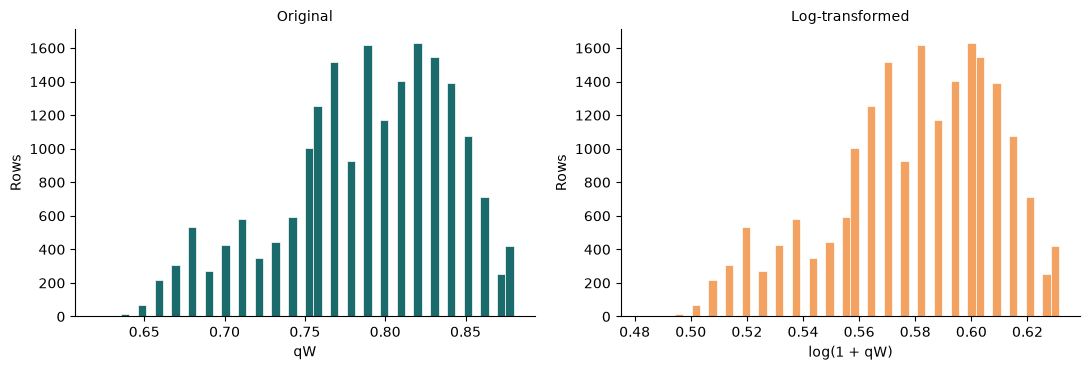

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); y = S[TGT].dropna().astype(float)
if y.nunique() <= 10:
    v = y.value_counts(normalize=True).sort_index() * 100; b = ax[0].bar(v.index.astype(str), v.values, color='#1B6B6D'); ax[0].bar_label(b, labels=['%.1f' % x for x in v.values], fontweight='bold'); ax[0].set_ylabel('Share of rows (%)')
    ax[1].axis('off'); print('class counts in the full table:', E[TGT].value_counts().to_dict())
else:
    ax[0].hist(y, bins=50, color='#1B6B6D', edgecolor='white', linewidth=0.5); ax[0].set_ylabel('Rows'); ax[0].set_xlabel(TGT)
    ax[1].hist(np.log1p(y.clip(lower=0)), bins=50, color='#F4A261', edgecolor='white', linewidth=0.5); ax[1].set_ylabel('Rows'); ax[1].set_xlabel('log(1 + ' + TGT + ')')
    ax[0].set_title('Original', fontsize=10); ax[1].set_title('Log-transformed', fontsize=10)
    print(y.describe(percentiles=[.05, .5, .95]).round(3).to_dict())
for a in ax: a.spines[['top', 'right']].set_visible(False)
fig.tight_layout(w_pad=1.5); fig.savefig('report/fig_eda_target.png', dpi=200); plt.show()

### 2b.6 Phân phối các cột số chính

- **Làm gì:** tám biểu đồ tần suất, đã cắt 1% hai đầu để nhìn rõ phần chính.
- **Kiểm tra:** cột có hai đỉnh thường ứng với hai chế độ vận hành, nên tách ra khi phân tích.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

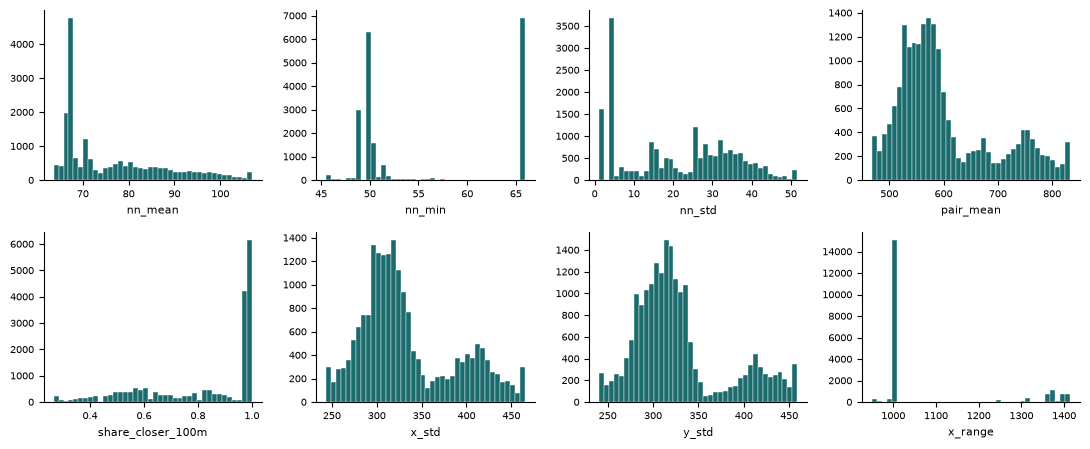

In [12]:
cols = [c for c in NUM if c != TGT][:8]; fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for a, c in zip(axes.ravel(), cols):
    x = S[c].dropna().astype(float); x = x.clip(x.quantile(.01), x.quantile(.99)); a.hist(x, bins=40, color='#1B6B6D', edgecolor='white', linewidth=0.3); a.set_xlabel(c, fontsize=8); a.spines[['top', 'right']].set_visible(False); a.tick_params(labelsize=7)
for a in axes.ravel()[len(cols):]: a.axis('off')
fig.tight_layout(); fig.savefig('report/fig_eda_distributions.png', dpi=200); plt.show()

### 2b.7 Giá trị ngoại lai

- **Làm gì:** tỷ lệ dòng nằm ngoài 1,5 lần khoảng tứ phân vị của từng cột.
- **Vì sao:** ngoại lai là lỗi đo thì loại và ghi nhật ký; là hiện tượng thật (đỉnh tải, sự cố) thì giữ và nêu trong bài.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [13]:
N_ = S[NUM].astype(float); q1, q3 = N_.quantile(.25), N_.quantile(.75); iqr = q3 - q1
out = (100 * ((N_ < q1 - 1.5 * iqr) | (N_ > q3 + 1.5 * iqr)).mean()).sort_values(ascending=False).round(2).rename('outside_1.5_IQR_pct')
out.to_csv('report/table_outliers.csv'); display(out.head(12).to_frame())

,outside_1.5_IQR_pct
x_range,43.02
y_range,23.62
total_power,20.25
n_wec,20.13
y_std,14.21
repeated,3.64
power_per_wec_kW,3.30
pair_mean,1.96
x_std,0.64
nn_mean,0.52


### 2b.8 Cột nào liên quan tới mục tiêu

- **Làm gì:** tương quan hạng Spearman giữa từng cột số và mục tiêu, vẽ mười cột mạnh nhất.
- **Vì sao:** đây là dự báo sớm về đặc trưng quan trọng; cột tương quan gần 1 có thể là rò rỉ và phải kiểm tra ý nghĩa.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,0
n_wec,-0.685
pairs_within_200m,0.655
power_per_wec_kW,0.649
y_range,-0.644
pairs_within_400m,0.617
y_std,-0.545
pair_mean,-0.531
x_std,-0.468
total_power,-0.302
nn_min,0.295


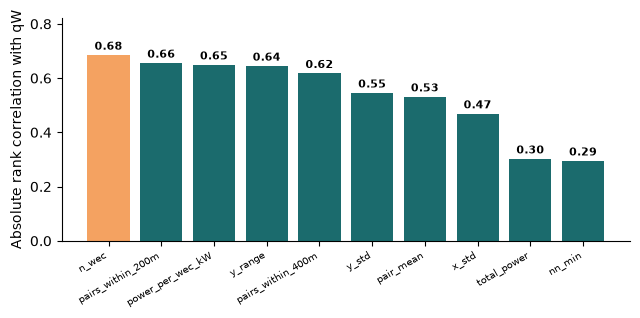

In [14]:
others = [c for c in NUM if c != TGT]
cor = S[others].astype(float).corrwith(S[TGT].astype(float), method='spearman').dropna(); cor = cor.reindex(cor.abs().sort_values(ascending=False).index).head(10)
cor.rename('spearman_with_target').to_csv('report/table_eda_correlation.csv'); display(cor.round(3).to_frame())
if len(cor) and cor.abs().max() > 0: bar_chart(cor.index, cor.abs().values, 'Absolute rank correlation with ' + TGT, 'report/fig_eda_correlation.png', highlight=0, fmt='{:.2f}')

### 2b.9 Các cột mạnh có trùng thông tin không

- **Làm gì:** ma trận tương quan giữa mục tiêu và bảy cột mạnh nhất.
- **Kiểm tra:** hai cột tương quan trên 0,95 với nhau thì chỉ cần giữ một khi giải thích kết quả.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

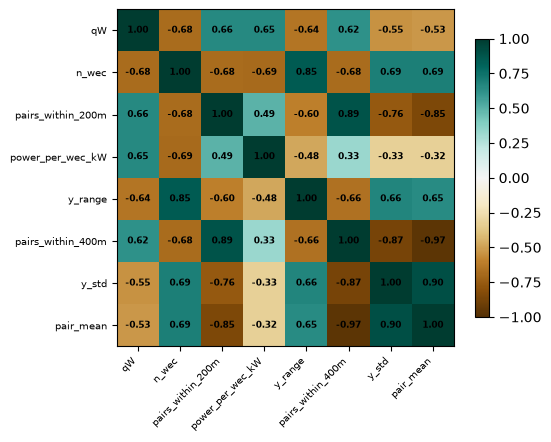

In [15]:
top = [TGT] + list(cor.index[:7]); m = S[top].astype(float).corr(method='spearman'); fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(m, cmap='BrBG', vmin=-1, vmax=1); ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top))); ax.set_xticklabels(top, rotation=45, ha='right', fontsize=7); ax.set_yticklabels(top, fontsize=7)
for i in range(len(top)):
    for j in range(len(top)): ax.text(j, i, '%.2f' % m.iloc[i, j], ha='center', va='center', fontsize=6.5, fontweight='bold')
fig.colorbar(im, shrink=0.8); fig.tight_layout(); fig.savefig('report/fig_eda_heatmap.png', dpi=200); plt.show()

### 2b.10 Mục tiêu theo nhóm

- **Làm gì:** số dòng, trung bình, trung vị và độ lệch chuẩn của mục tiêu theo cột nhóm, kèm hình.
- **Vì sao:** khác biệt giữa các nhóm là gợi ý trực tiếp cho RQ1 và cho cách chia dữ liệu ở Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,rows,mean,median,std
file,,,,
Perth_49,10936,0.825,0.82,0.027
Sydney_49,4816,0.769,0.77,0.016
Perth_100,2737,0.722,0.72,0.021
Sydney_100,1234,0.674,0.68,0.012


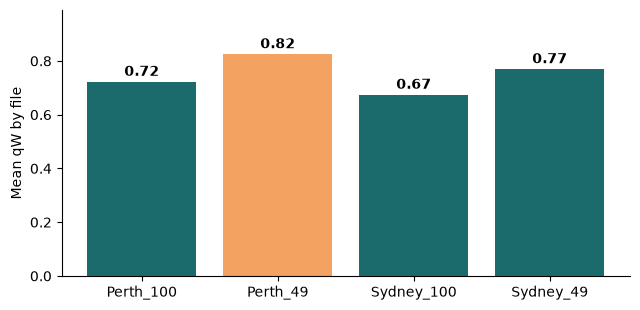

In [16]:
g = E.assign(_t=E[TGT].astype(float)).groupby(GRP)['_t'].agg(['size', 'mean', 'median', 'std']).rename(columns={'size': 'rows'})
g.to_csv('report/table_eda_by_group.csv'); display(g.sort_values('rows', ascending=False).head(15).round(3))
gg = g.sort_values('rows', ascending=False).head(12).sort_index()
if gg['mean'].min() >= 0 and gg['mean'].max() > 0: v, lab, f = nice(gg['mean'], 'Mean ' + TGT + ' by ' + GRP); bar_chart(gg.index.astype(str), v, lab, 'report/fig_eda_by_group.png', highlight=int(v.argmax()), fmt=f)

### Tổng hợp EDA

| Quan sát (có số) | Bằng chứng (bảng, hình) | Ảnh hưởng tới câu hỏi nào | Việc cần làm |
|---|---|---|---|
| | | | |
| | | | |
| | | | |
| | | | |
| | | | |

## Bước 3. Truy vấn dữ liệu bằng SQL

- **Làm gì:** ghi mọi truy vấn vào `sql/queries.sql`, rồi chạy **từng truy vấn một ô** để đọc kết quả và viết nhận xét.
- **Vì sao:** RQ1 được trả lời bằng bảng số; bảng `feat` là đầu vào của Notebook B.
- **Kiểm tra:** tính tay một nhóm nhỏ và so với kết quả truy vấn.

In [17]:
SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE wave AS SELECT * FROM 'data/processed/wave.parquet';
-- Q1: layouts and power by site and farm size
SELECT site, n_wec, COUNT(*) AS layouts, AVG(qW) AS mean_q_factor, MIN(qW) AS min_q, MAX(qW) AS max_q, AVG(power_per_wec_kW) AS kW_per_converter, SUM(repeated) AS repeated_layouts
FROM wave GROUP BY 1, 2 ORDER BY 1, 2;
-- Q2: q-factor by decile of the mean distance to the nearest converter (spacing drives the interaction between converters)
SELECT file, d AS spacing_decile, AVG(nn_mean) AS nearest_neighbour_m, AVG(qW) AS q_factor
FROM (SELECT *, NTILE(10) OVER (PARTITION BY file ORDER BY nn_mean) AS d FROM wave) GROUP BY 1, 2 ORDER BY 1, 2;
-- Q3: the four files ranked by the spread of the q-factor
SELECT file, STDDEV(qW) AS sd_q, RANK() OVER (ORDER BY STDDEV(qW) DESC) AS rank FROM wave GROUP BY 1 ORDER BY 3;
-- Q4: model table
CREATE OR REPLACE TABLE feat AS SELECT * FROM wave;
SELECT file, COUNT(*) AS n FROM feat GROUP BY 1 ORDER BY 1;
"""
open('sql/queries.sql', 'w').write(SQL)

1001

In [18]:
import duckdb
con = duckdb.connect(); QN = 0
def run(stmt):                                           # runs one statement; a SELECT is shown, saved and plotted when the result is small
    global QN
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if not body.upper().startswith(('SELECT', 'WITH', 'SUMMARIZE')): con.execute(stmt); print('done'); return None
    QN += 1; r = con.execute(stmt).df(); r.to_csv('report/table_q%d.csv' % QN, index=False); display(r.head(15))
    numc = [c for c in r.columns[1:] if pd.api.types.is_numeric_dtype(r[c])]
    if 2 <= len(r) <= 30 and numc and r[numc[0]].notna().all() and r[numc[0]].min() >= 0 and r[numc[0]].max() > 0:
        v, lab, f = nice(r[numc[0]], numc[0]); bar_chart(r.iloc[:, 0].astype(str), v, lab, 'report/fig_q%d.png' % QN, highlight=int(v.argmax()), fmt=f)
    return r

### Step 3: sql/queries.sql

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [19]:
r = run(r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE wave AS SELECT * FROM 'data/processed/wave.parquet';""")

done


### Q1: layouts and power by site and farm size

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,site,n_wec,layouts,mean_q_factor,min_q,max_q,kW_per_converter,repeated_layouts
0,Perth,49,10936,0.824585,0.72,0.88,79.467319,718.0
1,Perth,100,2737,0.721995,0.63,0.76,69.591569,0.0
2,Sydney,49,4816,0.768916,0.70,0.80,81.337588,0.0
3,Sydney,100,1234,0.673744,0.62,0.70,71.272584,0.0


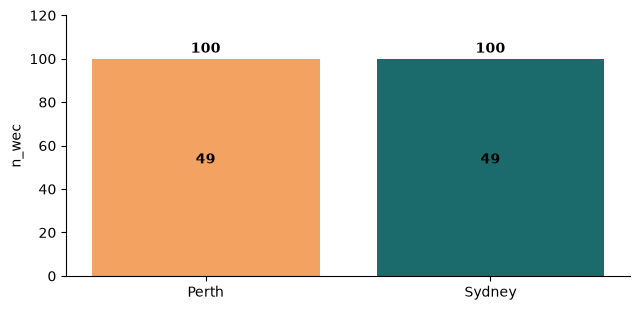

In [20]:
r = run(r"""-- Q1: layouts and power by site and farm size
SELECT site, n_wec, COUNT(*) AS layouts, AVG(qW) AS mean_q_factor, MIN(qW) AS min_q, MAX(qW) AS max_q, AVG(power_per_wec_kW) AS kW_per_converter, SUM(repeated) AS repeated_layouts
FROM wave GROUP BY 1, 2 ORDER BY 1, 2;""")

### Q2: q-factor by decile of the mean distance to the nearest converter (spacing drives the interaction between converters)

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [21]:
r = run(r"""-- Q2: q-factor by decile of the mean distance to the nearest converter (spacing drives the interaction between converters)
SELECT file, d AS spacing_decile, AVG(nn_mean) AS nearest_neighbour_m, AVG(qW) AS q_factor
FROM (SELECT *, NTILE(10) OVER (PARTITION BY file ORDER BY nn_mean) AS d FROM wave) GROUP BY 1, 2 ORDER BY 1, 2;""")

,file,spacing_decile,nearest_neighbour_m,q_factor
0,Perth_100,1,66.099899,0.736861
1,Perth_100,2,66.799888,0.724781
2,Perth_100,3,66.822148,0.724891
3,Perth_100,4,66.846918,0.729270
4,Perth_100,5,66.866963,0.724015
5,Perth_100,6,66.893492,0.724891
6,Perth_100,7,71.892583,0.724343
7,Perth_100,8,86.536104,0.715201
8,Perth_100,9,94.190166,0.709304
9,Perth_100,10,100.090309,0.706264


### Q3: the four files ranked by the spread of the q-factor

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,file,sd_q,rank
0,Perth_49,0.026617,1
1,Perth_100,0.020921,2
2,Sydney_49,0.015818,3
3,Sydney_100,0.012019,4


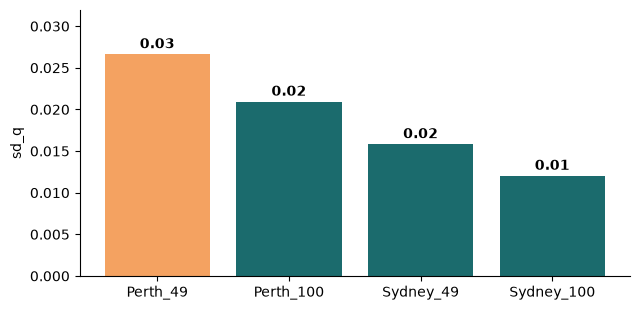

In [22]:
r = run(r"""-- Q3: the four files ranked by the spread of the q-factor
SELECT file, STDDEV(qW) AS sd_q, RANK() OVER (ORDER BY STDDEV(qW) DESC) AS rank FROM wave GROUP BY 1 ORDER BY 3;""")

### Q4: model table

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [23]:
r = run(r"""-- Q4: model table
CREATE OR REPLACE TABLE feat AS SELECT * FROM wave;""")

done


### Statement 6

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,file,n
0,Perth_100,2737
1,Perth_49,10936
2,Sydney_100,1234
3,Sydney_49,4816


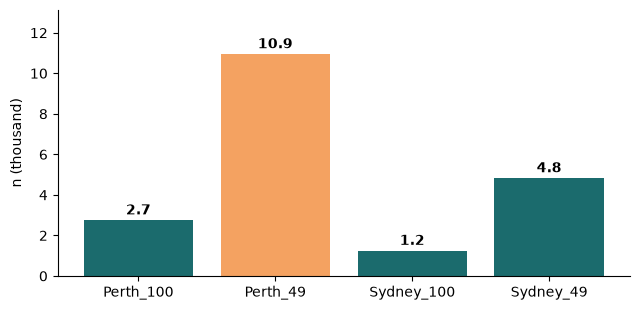

In [24]:
r = run(r"""SELECT file, COUNT(*) AS n FROM feat GROUP BY 1 ORDER BY 1;""")

### Truy vấn bổ sung 1: hồ sơ của bảng làm việc

- **Làm gì:** `SUMMARIZE` cho biết min, max, số giá trị khác nhau và tỷ lệ thiếu của mọi cột bằng một lệnh SQL.
- **Kiểm tra:** so với bảng thống kê mô tả ở mục 2b.3.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,column_name,column_type,min,max,approx_unique,null_percentage
0,nn_mean,DOUBLE,57.95990242145399,122.01401603553187,11703,0.0
1,nn_min,DOUBLE,4.703870746523416,75.71192574489172,1289,0.0
2,nn_std,DOUBLE,1.0410414993563621,85.28966628291869,10864,0.0
3,pair_mean,DOUBLE,401.8112470311273,901.0895313288706,23944,0.0
4,share_closer_100m,DOUBLE,0.08163265306122448,1.0,130,0.0
5,x_std,DOUBLE,185.43149395963806,515.2089862143323,11900,0.0
6,y_std,DOUBLE,182.69738304300415,524.637125249672,10045,0.0
7,x_range,DOUBLE,798.0,1450.0,471,0.0
8,y_range,DOUBLE,800.0,1450.0,450,0.0
9,pairs_within_200m,DOUBLE,0.0294,0.14743856726364016,274,0.0


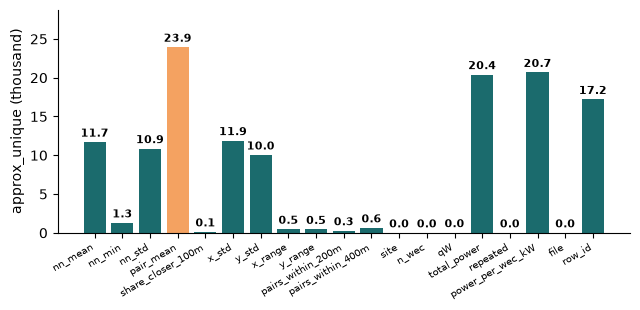

In [25]:
r = run('''SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE wave)''')

### Truy vấn bổ sung 2: các phân vị của mục tiêu

- **Làm gì:** phân vị 5%, 25%, 50%, 75%, 95% và 99% của cột mục tiêu.
- **Vì sao:** các phân vị này dùng để chọn ngưỡng, thang trục và cách cắt đuôi khi vẽ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [26]:
r = run('''SELECT COUNT(*) AS n, MIN("qW") AS min, QUANTILE_CONT("qW", 0.05) AS p05, QUANTILE_CONT("qW", 0.25) AS p25, MEDIAN("qW") AS p50, QUANTILE_CONT("qW", 0.75) AS p75, QUANTILE_CONT("qW", 0.95) AS p95, QUANTILE_CONT("qW", 0.99) AS p99, MAX("qW") AS max FROM wave''')

,n,min,p05,p25,p50,p75,p95,p99,max
0,19723,0.62,0.68,0.76,0.79,0.83,0.86,0.88,0.88


### Truy vấn bổ sung 3: xếp hạng các nhóm

- **Làm gì:** số dòng và trung bình mục tiêu theo nhóm, xếp hạng bằng hàm cửa sổ `RANK`, kèm tỷ trọng của nhóm trong toàn bảng.
- **Vì sao:** nhóm lớn nhất và nhóm lệch nhất thường là ví dụ minh hoạ trong mục Results.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,grp,mean_target,n,pct_of_rows,rank_by_mean
0,Perth_49,0.824585,10936,55.447954,1
1,Sydney_49,0.768916,4816,24.418192,2
2,Perth_100,0.721995,2737,13.877199,3
3,Sydney_100,0.673744,1234,6.256655,4


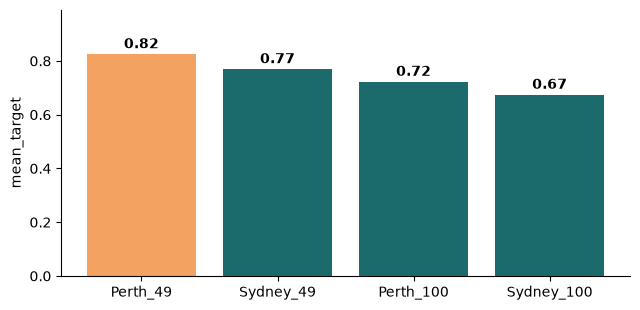

In [27]:
r = run('''SELECT CAST("file" AS VARCHAR) AS grp, AVG("qW") AS mean_target, COUNT(*) AS n, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_of_rows, RANK() OVER (ORDER BY AVG("qW") DESC) AS rank_by_mean FROM wave GROUP BY 1 ORDER BY 5 LIMIT 15''')

### Truy vấn bổ sung 4: bảng mô hình có sạch không

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu và số giá trị khác nhau của từng cột trong bảng `feat`.
- **Kiểm tra:** cột đặc trưng nào còn thiếu thì phải xử lý trước khi sang Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [28]:
r = run('''SELECT column_name, column_type, null_percentage, approx_unique FROM (SUMMARIZE feat) ORDER BY null_percentage DESC LIMIT 20''')

,column_name,column_type,null_percentage,approx_unique
0,nn_mean,DOUBLE,0.0,11703
1,nn_min,DOUBLE,0.0,1289
2,nn_std,DOUBLE,0.0,10864
3,pair_mean,DOUBLE,0.0,23944
4,share_closer_100m,DOUBLE,0.0,130
5,x_std,DOUBLE,0.0,11900
6,y_std,DOUBLE,0.0,10045
7,x_range,DOUBLE,0.0,471
8,y_range,DOUBLE,0.0,450
9,pairs_within_200m,DOUBLE,0.0,274


## Bước 5. Hình RQ1

- **Làm gì:** vẽ một biểu đồ cột từ kết quả SQL bằng hàm vẽ chuẩn của nhóm.
- **Vì sao:** người đọc phải thấy kết luận của RQ1 trong vài giây.
- **Kiểm tra:** chữ tiếng Anh, không viền trên và phải, số in đậm trên cột, không chữ đè cột. Viết caption nêu kết luận, không mô tả trục.

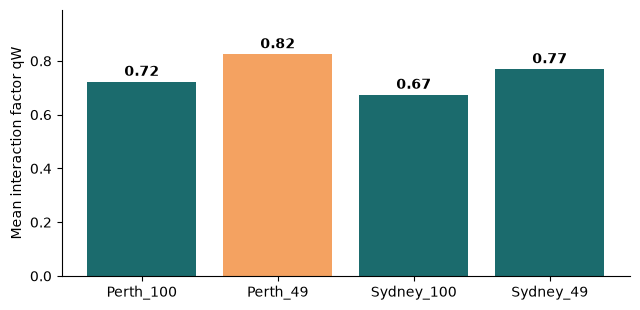

In [29]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""SELECT file AS g, AVG(qW) AS v FROM wave GROUP BY 1 ORDER BY 1""").df()
bar_chart(fig1.g, fig1.v, 'Mean interaction factor qW', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

## Bàn giao và test case

- **Làm gì:** ghi `manifest.json` (số dòng, số cột, mã băm) và chạy các kiểm tra tự động.
- **Vì sao:** Notebook B đọc manifest trước khi chạy, nên hai người làm song song mà không lệch dữ liệu.
- **Kiểm tra:** mọi `assert` qua. Sinh viên B chạy lại notebook này trên máy mình và ghi vào ô Đối chứng.

In [30]:
import json, hashlib
path = 'data/processed/wave.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n,
            'md5': hashlib.md5(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2); print(manifest)
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/wave.parquet', 'rows': 19723, 'columns': 19, 'feat_rows': 19723, 'md5': '314f7a6eb4afe05f8f7f183450bc720c'}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng | md5 khớp | Ghi chú |
|---|---|---|---|---|
| | | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: